# Graph — Prediksi Link (sisi mana yang akan muncul?)
**Kapan dipakai:** "rekomendasikan teman", "makalah mana yang akan saling mengutip", "produk
mana yang akan dibeli bersama" = menebak pasangan simpul yang (akan) tersambung.

**Idenya:** dua simpul yang punya banyak tetangga bersama cenderung tersambung. Skor heuristik
(common neighbors, Jaccard, Adamic-Adar, preferential attachment) dijadikan feature pasangan.

**Langkah:**
1. Sembunyikan 10% sisi sebagai uji; buat contoh negatif (pasangan yang tidak tersambung).
2. Hitung skor heuristik tiap pasangan di graf train.
3. Model belajar dari skor itu; evaluasi AUC dan AP; simpan skor pasangan uji.

**Data demo:** Cora (sisi = sitasi, nomor simpul 0..2707).

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/graph/cora"   # GANTI saat lomba
NODES_CSV = f"{DATA_FOLDER}/nodes.csv"
EDGES_CSV = f"{DATA_FOLDER}/edges.csv"

NODE_ID_COL = "id"
SOURCE_COL = "source"
TARGET_COL = "target"
TEST_FRACTION = 0.1     # porsi sisi yang disembunyikan sebagai uji
SCORE_NAMES = ["common_neighbors", "jaccard", "adamic_adar", "log_pref_attach"]
SEED = 42

## Baca data
Sisi disimpan sebagai (simpul kecil, simpul besar) supaya (a, b) dan (b, a) dianggap sama.

In [3]:
nodes = pd.read_csv(NODES_CSV, usecols=[NODE_ID_COL])
edges = pd.read_csv(EDGES_CSV)
N_NODES = len(nodes)
true_edges = set()
for node_a, node_b in zip(edges[SOURCE_COL], edges[TARGET_COL]):
    if node_a != node_b:                          # buang sisi ke diri sendiri
        true_edges.add((min(node_a, node_b), max(node_a, node_b)))
print(N_NODES, "simpul,", len(true_edges), "sisi tak berarah")

2708 simpul, 5278 sisi tak berarah


## Langkah 1a — split sisi
Sisi uji dihapus dari graf train, jadi model tidak bisa "melihat" jawabannya.

In [4]:
edge_array = np.array(sorted(true_edges))
train_edges, test_edges = train_test_split(edge_array, test_size=TEST_FRACTION,
                                           random_state=SEED)
train_graph = nx.Graph()
train_graph.add_nodes_from(range(N_NODES))
train_graph.add_edges_from(train_edges.tolist())
print("train:", len(train_edges), "sisi | uji:", len(test_edges), "sisi")

train: 4750 sisi | uji: 528 sisi


## Langkah 1b — contoh negatif
Pasangan simpul acak yang TIDAK tersambung di graf asli, sama banyak dengan contoh positif.

In [5]:
def sample_negatives(count, rng):
    negatives = set()
    while len(negatives) < count:
        node_a, node_b = rng.integers(0, N_NODES, size=2)
        pair = (min(node_a, node_b), max(node_a, node_b))
        if node_a != node_b and pair not in true_edges:
            negatives.add(pair)
    return np.array(sorted(negatives))


rng = np.random.default_rng(SEED)
train_negatives = sample_negatives(len(train_edges), rng)
test_negatives = sample_negatives(len(test_edges), rng)
train_pairs = np.vstack([train_edges, train_negatives])
y_train = np.concatenate([np.ones(len(train_edges)), np.zeros(len(train_negatives))])
test_pairs = np.vstack([test_edges, test_negatives])
y_test = np.concatenate([np.ones(len(test_edges)), np.zeros(len(test_negatives))])
print("pasangan train:", len(train_pairs), "| pasangan uji:", len(test_pairs))

pasangan train: 9500 | pasangan uji: 1056


## Langkah 2 — skor heuristik per pasangan (dihitung di graf train)
- **common_neighbors:** jumlah tetangga bersama.  **jaccard:** tetangga bersama / gabungan.
- **adamic_adar:** tetangga bersama, yang tetangganya sedikit diberi bobot lebih besar.
- **log_pref_attach:** log(derajat a x derajat b), simpul populer cenderung tersambung.

In [6]:
def pair_features(graph, pairs):
    rows = []
    for node_a, node_b in pairs:
        common = list(nx.common_neighbors(graph, node_a, node_b))
        degree_a = graph.degree(node_a)
        degree_b = graph.degree(node_b)
        union = degree_a + degree_b - len(common)
        jaccard = 0
        if union > 0:
            jaccard = len(common) / union
        adamic_adar = 0
        for neighbor in common:
            adamic_adar += 1 / np.log(graph.degree(neighbor))
        rows.append([len(common), jaccard, adamic_adar, np.log1p(degree_a * degree_b)])
    return pd.DataFrame(rows, columns=SCORE_NAMES)


X_train = pair_features(train_graph, train_pairs)
X_test = pair_features(train_graph, test_pairs)
print("AUC tiap skor heuristik sendirian (pembanding):")
for name in SCORE_NAMES:
    print(f"  {name:20s} {roc_auc_score(y_test, X_test[name]):.3f}")
X_train.head()

AUC tiap skor heuristik sendirian (pembanding):


  common_neighbors     0.734
  jaccard              0.734
  adamic_adar          0.734
  log_pref_attach      0.664


,common_neighbors,jaccard,adamic_adar,log_pref_attach
0,0,0.000000,0.000000,2.944439
1,1,0.100000,0.480898,3.218876
2,0,0.000000,0.000000,1.945910
3,0,0.000000,0.000000,3.583519
4,1,0.052632,1.442695,3.610918


## Langkah 3 — model
Pilih SATU model: hapus `#` di depan baris yang ingin dipakai, beri `#` pada baris lain.

In [7]:
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
# model = make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=300,
#                                                                random_state=SEED))
# model = LGBMClassifier(n_estimators=300, learning_rate=0.05, verbose=-1, random_state=SEED)
# model = ExtraTreesClassifier(n_estimators=300, random_state=SEED)
# model = XGBClassifier(n_estimators=300, learning_rate=0.05, random_state=SEED)
# model = HistGradientBoostingClassifier(random_state=SEED)

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[float64](2,)","[0.,1.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['common_neighbors','jaccard','adamic_adar','log_pref_attach']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


## Evaluasi (AUC dan AP)
AUC = seberapa sering sisi asli diberi skor lebih tinggi dari bukan-sisi (1 = sempurna).

AUC model: 0.7681
AP model : 0.836


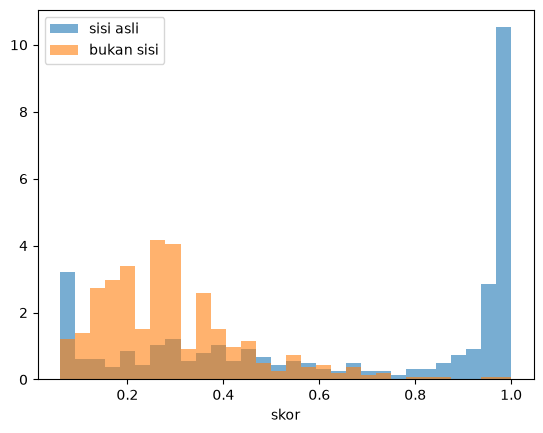

In [8]:
test_probabilities = model.predict_proba(X_test)
test_scores = test_probabilities[:, 1]          # peluang "tersambung"
print("AUC model:", round(roc_auc_score(y_test, test_scores), 4))
print("AP model :", round(average_precision_score(y_test, test_scores), 4))
plt.hist(test_scores[y_test == 1], bins=30, alpha=0.6, density=True, label="sisi asli")
plt.hist(test_scores[y_test == 0], bins=30, alpha=0.6, density=True, label="bukan sisi")
plt.xlabel("skor")
plt.legend()
plt.show()

## Simpan skor pasangan uji

In [9]:
submission = pd.DataFrame()
submission["source"] = test_pairs[:, 0]
submission["target"] = test_pairs[:, 1]
submission["score"] = test_scores
submission.to_csv("submission.csv", index=False)
submission.head()

,source,target,score
0,2,552,0.781468
1,1550,1555,0.999364
2,123,553,0.060035
3,430,547,0.533535
4,1283,1318,0.996412
